### Exploratory Data Anlysis

##### Adding library and importing datasets

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
df_mat = pd.read_csv("data/student-mat.csv", sep=";")
df_por = pd.read_csv("data/student-por.csv", sep=";")

##### Concatinating 2 dataframes

In [3]:
df_all = pd.concat([df_mat, df_por], axis=0, ignore_index=True)

##### Box plot

##### Bài tập 1: Vẽ boxplot trường MS GD (school) theo G3 

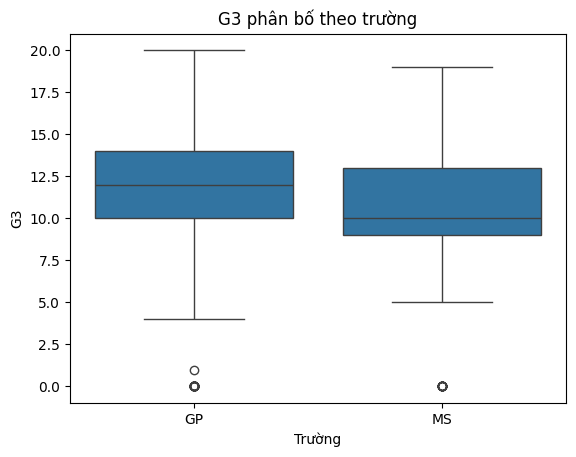

In [7]:
# Bài tập 1: Vẽ boxplot trường MS GD (school) theo G3 
sns.boxplot(x="school", y="G3", data=df_all)
plt.title("G3 phân bố theo trường")
plt.xlabel("Trường")
plt.ylabel("G3")
plt.show()


##### Bài tập 2: Vẽ 3 boxplot của trường MS và GD theo điểm G1, G2, G3

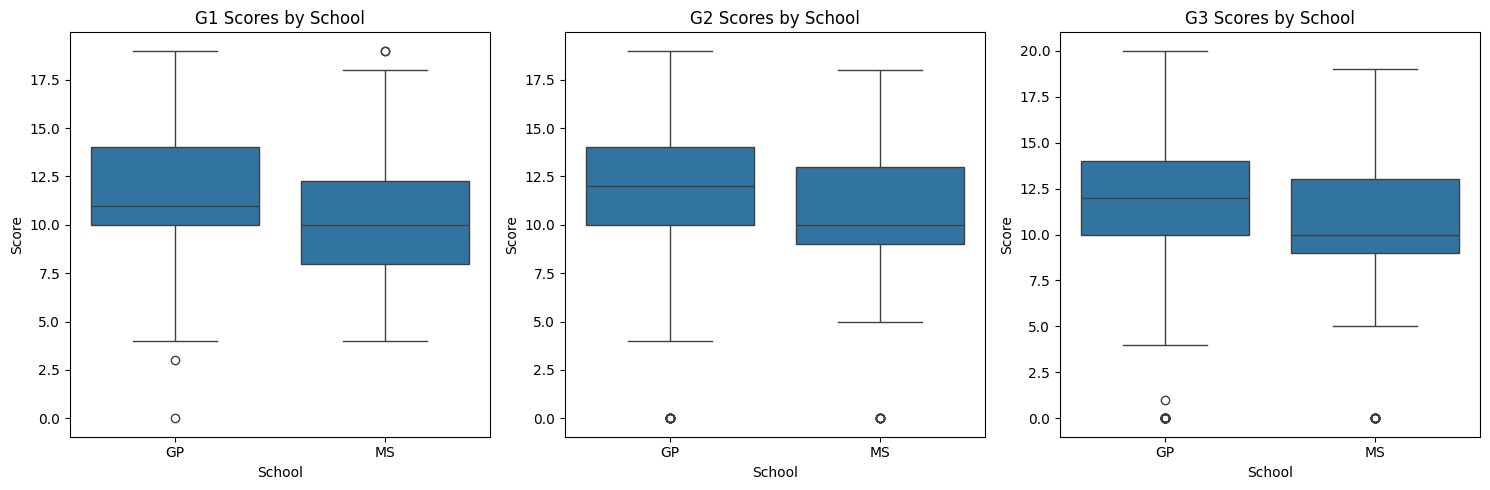

In [ ]:
# Bài tập 2: Vẽ 3 boxplot của trường MS và GD theo điểm G1, G2, G3
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Boxplot G1
sns.boxplot(x="school", y="G1", data=df_all, ax=axes[0])
axes[0].set_title("G1 theo trường")
axes[0].set_xlabel("School")
axes[0].set_ylabel("Điểm")

# Boxplot G2
sns.boxplot(x="school", y="G2", data=df_all, ax=axes[1])
axes[1].set_title("G2 theo trường")
axes[1].set_xlabel("School")
axes[1].set_ylabel("Điểm")

# Boxplot G3
sns.boxplot(x="school", y="G3", data=df_all, ax=axes[2])
axes[2].set_title("G3 theo trường")
axes[2].set_xlabel("School")
axes[2].set_ylabel("Điểm")

plt.tight_layout()
plt.show()

##### Bài tập 3: Vẽ violin của trường MS và GD cho điểm G1

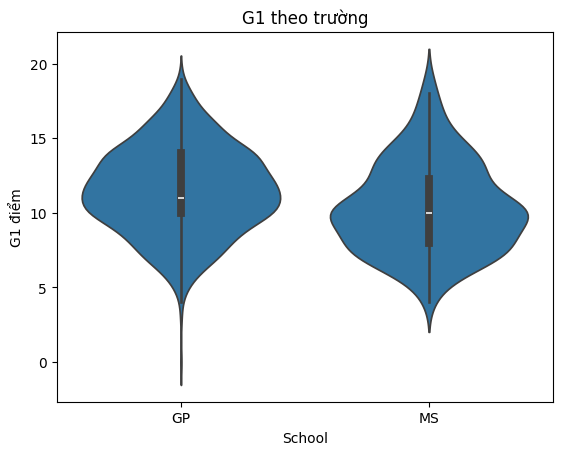

In [10]:
# Bài tập 3: Vẽ violin của trường MS và GD cho điểm G1
sns.violinplot(x="school", y="G1", data=df_all)

plt.title("G1 theo trường")
plt.xlabel("School")
plt.ylabel("G1 điểm")
plt.show()


##### Bài tập 4: Tìm ngoại lệ thấp cao theo trường MS và GP của điểm G3

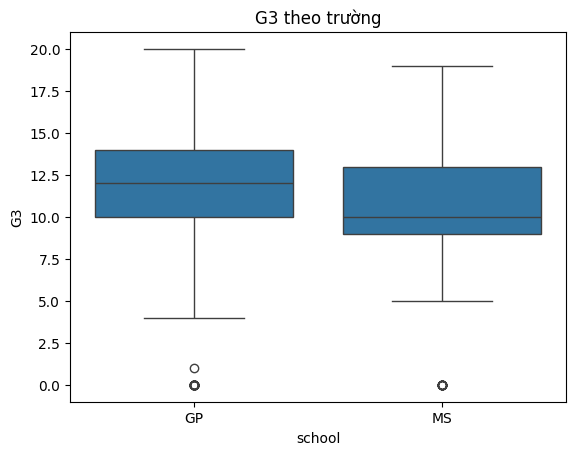

In [11]:
# Bài tập 4: Tìm ngoại lệ thấp cao theo trường MS và GP của điểm G3
sns.boxplot(x="school", y="G3", data=df_all, showfliers=True)
plt.title("G3 theo trường")
plt.show()

##### Bài tập 5: Xét tương quan của G1, G2, G3, studytime. Xét xem dùng phương thức gì? Phải có 2 cái heatmap, sài 2 cách khác nhau

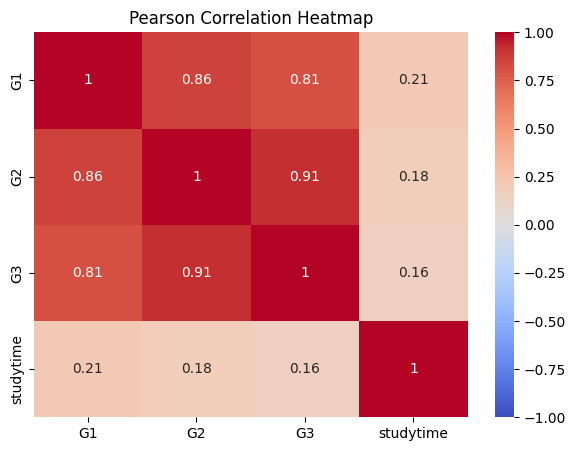

In [ ]:
# Bài tập 5: Xét tương quan của G1, G2, G3, studytime. Xét xem dùng phương thức gì? Phải có 2 cái heatmap, sài 2 cách khác nhau
cols = ['G1', 'G2', 'G3', 'studytime']

corr_pearson = df_all[cols].corr(method='pearson')

plt.figure(figsize=(7, 5))
sns.heatmap(corr_pearson, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Heatmap tương quan Pearson')
plt.show()

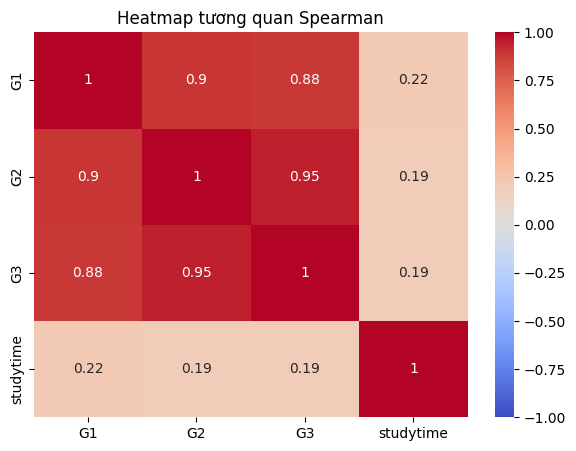

In [14]:
corr_spearman = df_all[cols].corr(method='spearman')

plt.figure(figsize=(7, 5))
sns.heatmap(corr_spearman, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Heatmap tương quan Spearman')
plt.show()

### Academic Performance - Kết quả học tập

* Goal: 
    - Theo dõi và cải thiện chất lượng điểm số đầu ra (cuối kì), đồng thời đảm bảo sự ổn định
      học lực của học sinh qua các giai đoạn kiểm tra (dashboard này tập trung vào phân chia 2 môn hơn là phân chia 
      giữa 2 trường nhằm chỉ nhấn mạnh vào kết quả thi)

* Metrics: 
    - Điểm trung bình các bài thi (G1, G2, G3)
    - Tỷ lệ phần trăm học sinh qua môn (G3 >=10) 
    - Sự chênh lệch điểm số giữa các kì

* Key Result: 
    - Tăng điểm trung bình cuối kì lên mức tối thiếu 
    - Giảm tỷ lệ học sinh rớt môn - xuống dưới một mức nào đó 
    - Rút ngắn khoảng cách sụt giảm điểm số giữa G1 và G3


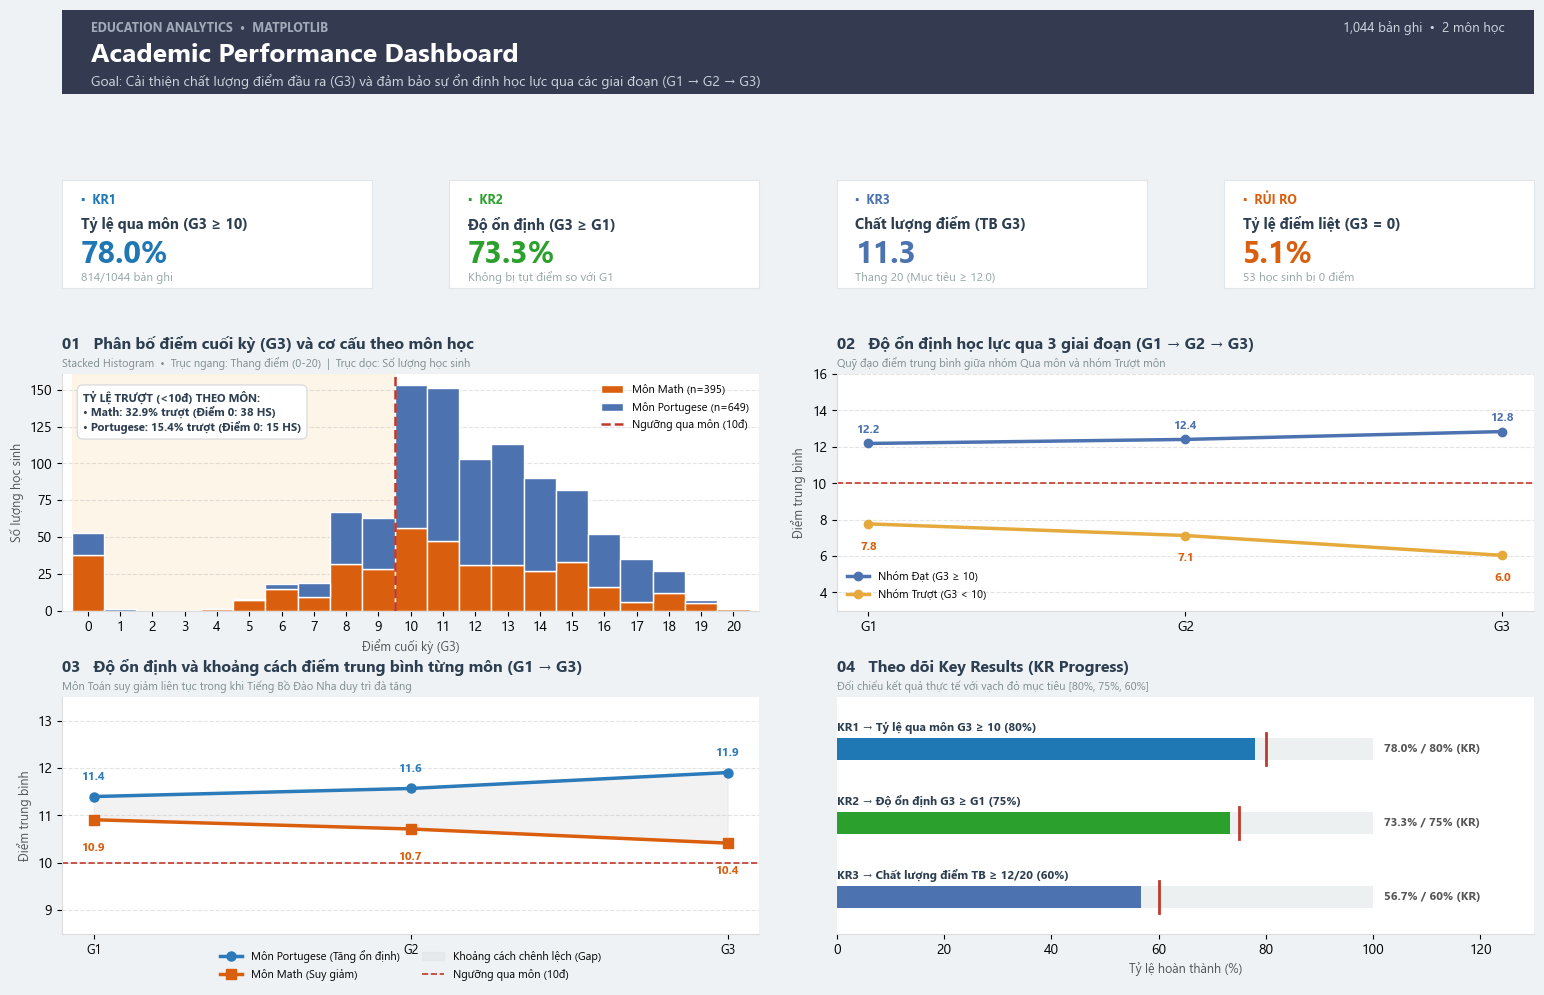

In [29]:
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.patches import FancyBboxPatch
import numpy as np
import pandas as pd

df = df_all.copy() 
total_records = len(df)

subj_col = 'subject'
# Tính toán các chỉ số KPI & Key Results
kr1_pass_rate = (df['G3'] >= 10).mean() * 100          # KR1: Tỷ lệ qua môn (Mục tiêu >= 80%)
kr2_stable_rate = (df['G3'] >= df['G1']).mean() * 100  # KR2: Ổn định G3 >= G1 (Mục tiêu >= 75%)
avg_g3 = df['G3'].mean()                               # Điểm TB G3 (Mục tiêu >= 12.0)
kr3_score_pct = (avg_g3 / 20.0) * 100                  # Quy đổi Điểm TB sang % (12/20 = 60%)
zero_rate = (df['G3'] == 0).mean() * 100              
zero_count = (df['G3'] == 0).sum()


# BƯỚC 1: THIẾT LẬP BỐ CỤC GRIDSPEC (4 HÀNG x 4 CỘT VỪA KHÍT 4 BIỂU ĐỒ)
plt.rcParams['font.sans-serif'] = 'Segoe UI'
plt.rcParams['axes.edgecolor'] = '#dcdcdc'

fig = plt.figure(figsize=(16, 10.5), facecolor='#eef2f5')
gs = GridSpec(4, 4, figure=fig, height_ratios=[0.78, 1.0, 2.2, 2.2], hspace=0.52, wspace=0.25)

# TITLES
ax_header = fig.add_subplot(gs[0, :])
ax_header.axis('off')
banner = FancyBboxPatch((0, 0), 1, 1, boxstyle="round,pad=0.02,rounding_size=0.03",
                        facecolor='#343a50', edgecolor='none', transform=ax_header.transAxes)
ax_header.add_patch(banner)

ax_header.text(0.02, 0.74, "EDUCATION ANALYTICS  •  MATPLOTLIB", fontsize=9, color='#a0aab8', fontweight='bold')
ax_header.text(0.02, 0.38, "Academic Performance Dashboard", fontsize=19, color='white', fontweight='bold')
ax_header.text(0.02, 0.10, "Goal: Cải thiện chất lượng điểm đầu ra (G3) và đảm bảo sự ổn định học lực qua các giai đoạn (G1 → G2 → G3)", 
               fontsize=10, color='#cfd6e0')
ax_header.text(0.98, 0.74, f"{total_records:,} bản ghi  •  2 môn học", fontsize=9.5, color='#cfd6e0', ha='right')

# KPI CARDS
kpi_configs = [
    ("KR1", "Tỷ lệ qua môn (G3 ≥ 10)", f"{kr1_pass_rate:.1f}%", f"{(df['G3']>=10).sum()}/{total_records} bản ghi", "#1f77b4"),
    ("KR2", "Độ ổn định (G3 ≥ G1)", f"{kr2_stable_rate:.1f}%", "Không bị tụt điểm so với G1", "#2ca02c"),
    ("KR3", "Chất lượng điểm (TB G3)", f"{avg_g3:.1f}", "Thang 20 (Mục tiêu ≥ 12.0)", "#4c72b0"),
    ("RỦI RO", "Tỷ lệ điểm liệt (G3 = 0)", f"{zero_rate:.1f}%", f"{zero_count} học sinh bị 0 điểm", "#d95f0e")
]

for col_idx, (tag, title, val, sub, color) in enumerate(kpi_configs):
    ax_kpi = fig.add_subplot(gs[1, col_idx])
    ax_kpi.set_facecolor('white')
    ax_kpi.set_xticks([]); ax_kpi.set_yticks([])
    for spine in ax_kpi.spines.values():
        spine.set_edgecolor('#e1e6eb')
    ax_kpi.text(0.06, 0.78, f"▪  {tag}", fontsize=9, color=color, fontweight='bold')
    ax_kpi.text(0.06, 0.55, title, fontsize=10.5, color='#2c3e50', fontweight='bold')
    ax_kpi.text(0.06, 0.23, val, fontsize=22, color=color, fontweight='bold')
    ax_kpi.text(0.06, 0.06, sub, fontsize=8.5, color='#95a5a6')

# BIỂU ĐỒ 01 (Trái - Trên): STACKED HISTOGRAM ĐIỂM G3 THEO MÔN HỌC
ax1 = fig.add_subplot(gs[2, 0:2])
ax1.set_facecolor('white')

s_names = list(df[subj_col].unique())
math_name = [s for s in s_names if 'math' in str(s).lower() or 'toán' in str(s).lower()]
math_name = math_name[0] if math_name else s_names[0]
por_name = [s for s in s_names if s != math_name][0] if len(s_names) > 1 else math_name

g3_math = df[df[subj_col] == math_name]['G3']
g3_por = df[df[subj_col] == por_name]['G3']

ax1.axvspan(-0.5, 9.5, color='#fdebd0', alpha=0.45, zorder=1)

bins = np.arange(0, 22, 1) - 0.5
ax1.hist([g3_math, g3_por], bins=bins, stacked=True, 
         color=['#d95f0e', '#4c72b0'], edgecolor='white', linewidth=1.0, zorder=2,
         label=[f'Môn {math_name} (n={len(g3_math)})', f'Môn {por_name} (n={len(g3_por)})'])

ax1.axvline(x=9.5, color='#c0392b', linestyle='--', linewidth=1.8, zorder=3, label='Ngưỡng qua môn (10đ)')

math_fail_pct = (g3_math < 10).mean() * 100
por_fail_pct = (g3_por < 10).mean() * 100
summary_text = (
    f"TỶ LỆ TRƯỢT (<10đ) THEO MÔN:\n"
    f"• {math_name}: {math_fail_pct:.1f}% trượt (Điểm 0: {(g3_math==0).sum()} HS)\n"
    f"• {por_name}: {por_fail_pct:.1f}% trượt (Điểm 0: {(g3_por==0).sum()} HS)"
)
ax1.text(0.03, 0.93, summary_text, transform=ax1.transAxes, fontsize=8.2,
         verticalalignment='top', color='#2c3e50', fontweight='bold', zorder=4,
         bbox=dict(boxstyle='round,pad=0.5', facecolor='white', edgecolor='#dcdcdc', lw=1))

ax1.set_title("01   Phân bố điểm cuối kỳ (G3) và cơ cấu theo môn học", fontsize=11.5, fontweight='bold', loc='left', pad=18, color='#2c3e50')
ax1.text(0, 1.03, "Stacked Histogram  •  Trục ngang: Thang điểm (0-20)  |  Trục dọc: Số lượng học sinh", transform=ax1.transAxes, fontsize=8, color='#7f8c8d')
ax1.set_xticks(range(0, 21, 1))
ax1.set_xlim(-0.8, 20.8)
ax1.set_xlabel("Điểm cuối kỳ (G3)", fontsize=9, color='#555555', labelpad=4)
ax1.set_ylabel("Số lượng học sinh", fontsize=9, color='#555555')
ax1.grid(axis='y', linestyle='--', alpha=0.35, zorder=0)
ax1.spines['top'].set_visible(False); ax1.spines['right'].set_visible(False)
ax1.legend(frameon=False, fontsize=8, loc='upper right')

# BIỂU ĐỒ 02 (Phải - Trên): ĐỘ ỔN ĐỊNH HỌC LỰC QUA 3 GIAI ĐOẠN (NHÓM ĐẠT VS TRƯỢT)
ax2 = fig.add_subplot(gs[2, 2:4])
ax2.set_facecolor('white')

pass_group = df[df['G3'] >= 10][['G1', 'G2', 'G3']].mean()
fail_group = df[df['G3'] < 10][['G1', 'G2', 'G3']].mean()
periods = ['G1', 'G2', 'G3']

ax2.plot(periods, pass_group, marker='o', linewidth=2.5, markersize=6, color='#4c72b0', label='Nhóm Đạt (G3 ≥ 10)')
ax2.plot(periods, fail_group, marker='o', linewidth=2.5, markersize=6, color='#e5a93c', label='Nhóm Trượt (G3 < 10)')
ax2.axhline(y=10, color='#c0392b', linestyle='--', linewidth=1.2)

for i, (p_val, f_val) in enumerate(zip(pass_group, fail_group)):
    ax2.text(i, p_val + 0.6, f"{p_val:.1f}", ha='center', fontsize=8.5, fontweight='bold', color='#4c72b0')
    ax2.text(i, f_val - 1.4, f"{f_val:.1f}", ha='center', fontsize=8.5, fontweight='bold', color='#d95f0e')

ax2.set_title("02   Độ ổn định học lực qua 3 giai đoạn (G1 → G2 → G3)", fontsize=11.5, fontweight='bold', loc='left', pad=18, color='#2c3e50')
ax2.text(0, 1.03, "Quỹ đạo điểm trung bình giữa nhóm Qua môn và nhóm Trượt môn", transform=ax2.transAxes, fontsize=8, color='#7f8c8d')
ax2.set_ylim(3, 16)
ax2.set_ylabel("Điểm trung bình", fontsize=9, color='#555555')
ax2.grid(axis='y', linestyle='--', alpha=0.35)
ax2.spines['top'].set_visible(False); ax2.spines['right'].set_visible(False)
ax2.legend(frameon=False, fontsize=8, loc='lower left')

# BIỂU ĐỒ 03 (Trái - Dưới): ĐỘ ỔN ĐỊNH & KHOẢNG CÁCH PHÂN HÓA 2 MÔN (G1 -> G3)
ax3 = fig.add_subplot(gs[3, 0:2])
ax3.set_facecolor('white')

subj_means = df.groupby(subj_col)[['G1', 'G2', 'G3']].mean()
stages = ['G1', 'G2', 'G3']
x_idx = np.arange(len(stages))

y_math = subj_means.loc[math_name, ['G1', 'G2', 'G3']].values
y_por = subj_means.loc[por_name, ['G1', 'G2', 'G3']].values

ax3.plot(x_idx, y_por, marker='o', linewidth=2.5, markersize=6.5, color='#2b7bba', label=f"Môn {por_name} (Tăng ổn định)")
ax3.plot(x_idx, y_math, marker='s', linewidth=2.5, markersize=6.5, color='#d95f0e', label=f"Môn {math_name} (Suy giảm)")
ax3.fill_between(x_idx, y_math, y_por, color='#dcdcdc', alpha=0.35, label='Khoảng cách chênh lệch (Gap)')

for i in range(len(stages)):
    ax3.text(i, y_por[i] + 0.35, f"{y_por[i]:.1f}", ha='center', fontsize=8.5, fontweight='bold', color='#2b7bba')
    ax3.text(i, y_math[i] - 0.65, f"{y_math[i]:.1f}", ha='center', fontsize=8.5, fontweight='bold', color='#d95f0e')

ax3.axhline(y=10, color='#c0392b', linestyle='--', linewidth=1.2, label='Ngưỡng qua môn (10đ)')

ax3.set_title("03   Độ ổn định và khoảng cách điểm trung bình từng môn (G1 → G3)", fontsize=11.5, fontweight='bold', loc='left', pad=18, color='#2c3e50')
ax3.text(0, 1.03, "Môn Toán suy giảm liên tục trong khi Tiếng Bồ Đào Nha duy trì đà tăng", transform=ax3.transAxes, fontsize=8, color='#7f8c8d')
ax3.set_xticks(x_idx); ax3.set_xticklabels(stages, fontsize=9)
ax3.set_ylim(8.5, 13.5)
ax3.set_ylabel("Điểm trung bình", fontsize=9, color='#555555')
ax3.grid(axis='y', linestyle='--', alpha=0.35)
ax3.spines['top'].set_visible(False); ax3.spines['right'].set_visible(False)
ax3.legend(loc='lower center', bbox_to_anchor=(0.5, -0.24), ncol=2, frameon=False, fontsize=8)

# BIỂU ĐỒ 04 (Phải - Dưới): THEO DÕI KEY RESULTS (KR PROGRESS)
ax4 = fig.add_subplot(gs[3, 2:4])
ax4.set_facecolor('white')

kr_labels = [
    "KR3 → Chất lượng điểm TB ≥ 12/20 (60%)",
    "KR2 → Độ ổn định G3 ≥ G1 (75%)",
    "KR1 → Tỷ lệ qua môn G3 ≥ 10 (80%)"
]
actuals = [kr3_score_pct, kr2_stable_rate, kr1_pass_rate]
targets = [60.0, 75.0, 80.0]
bar_colors = ['#4c72b0', '#2ca02c', '#1f77b4']

y_pos = np.arange(len(kr_labels))
ax4.barh(y_pos, [100, 100, 100], height=0.30, color='#ecf0f1')
ax4.barh(y_pos, actuals, height=0.30, color=bar_colors)

for i, (act, targ, label) in enumerate(zip(actuals, targets, kr_labels)):
    ax4.plot([targ, targ], [i - 0.22, i + 0.22], color='#c0392b', linewidth=2)
    ax4.text(0, i + 0.25, label, fontsize=8.5, fontweight='bold', color='#2c3e50')
    ax4.text(102, i, f"{act:.1f}% / {targ:.0f}% (KR)", va='center', fontsize=8.5, fontweight='bold', color='#555555')

ax4.set_title("04   Theo dõi Key Results (KR Progress)", fontsize=11.5, fontweight='bold', loc='left', pad=18, color='#2c3e50')
ax4.text(0, 1.03, "Đối chiếu kết quả thực tế với vạch đỏ mục tiêu [80%, 75%, 60%]", transform=ax4.transAxes, fontsize=8, color='#7f8c8d')
ax4.set_xlim(0, 130)
ax4.set_ylim(-0.5, 2.7)
ax4.set_yticks([])
ax4.set_xlabel("Tỷ lệ hoàn thành (%)", fontsize=9, color='#555555', labelpad=4)
ax4.spines['top'].set_visible(False); ax4.spines['right'].set_visible(False); ax4.spines['left'].set_visible(False)

plt.subplots_adjust(left=0.04, right=0.96, top=0.95, bottom=0.07)
plt.show()

### Student Risk Monitoring - Cảnh báo nguy cơ

### Attendance & Study Habits - Chuyên cần và thói quen

### Educational Support - Hỗ trợ học tập

### Educational Equity - Công bằng giáo dục